Step 10: UnivariateCox Consensus Gene Ranking
This notebook combines the gene-derived feature rankings from the three DeepSurv XAI methods: DeepSHAP-style DeepLiftShap, Integrated Gradients, and GradientSHAP. The goal is to identify candidate prognostic gene features that are consistently important across methods. The consensus unit is the exact model feature, such as MUT_TP53 or CNA_CDKN2A, because mutation and copy-number alteration can carry different biological and model meanings.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%pip install -q matplotlib-venn lifelines

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 12.2 MB/s eta 0:00:00


In [3]:
import os
import pickle
import platform
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib_venn import venn3

import lifelines
from IPython.display import display

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")

Reproducibility information

In [4]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("lifelines:", lifelines.__version__)
print("Random state:", RANDOM_STATE)

Python: 3.12.13
NumPy: 2.0.2
Pandas: 2.2.2
lifelines: 0.30.3
Random state: 42


In [5]:
RESULTS_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/"
XAI_RESULTS_DIR = RESULTS_DIR + "XAI/"
MODEL_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Model/UnivariateCox/"

COXPH_MODEL_PATH = MODEL_DIR + "hcc_UniCox_coxph_model.pkl"

DEEPSHAP_GENE_PATH = XAI_RESULTS_DIR + "unicox_deepsurv_deepshap_top_gene_features.csv"
IG_GENE_PATH = XAI_RESULTS_DIR + "unicox_deepsurv_integrated_gradients_top_gene_features.csv"
GRADIENTSHAP_GENE_PATH = XAI_RESULTS_DIR + "unicox_deepsurv_gradientshap_top_gene_features.csv"

CONSENSUS_TABLE_PATH = XAI_RESULTS_DIR + "unicox_consensus_candidate_prognostic_gene_features.csv"
CONSENSUS_TOP_TABLE_PATH = XAI_RESULTS_DIR + "unicox_consensus_candidate_prognostic_gene_features_top.csv"
VENN_PLOT_PATH = XAI_RESULTS_DIR + "unicox_consensus_gene_venn_diagram.png"
BAR_PLOT_PATH = XAI_RESULTS_DIR + "unicox_consensus_gene_ranking_barplot.png"
DIRECTION_HEATMAP_PATH = XAI_RESULTS_DIR + "unicox_consensus_gene_direction_heatmap.png"

TOP_N_GENES_PER_METHOD = 30
CONSENSUS_MIN_METHODS = 2
TOP_N_DISPLAY = 30

os.makedirs(XAI_RESULTS_DIR, exist_ok=True)

print("XAI results directory:", XAI_RESULTS_DIR)

XAI results directory: /content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/XAI/


Load XAI gene rankings from Step 9
Run step_9_UnCox_DeepSurv_XAI.ipynb first so these files exist.

In [7]:
required_files = {
    "DeepSHAP-style DeepLiftShap": DEEPSHAP_GENE_PATH,
    "Integrated Gradients": IG_GENE_PATH,
    "GradientSHAP": GRADIENTSHAP_GENE_PATH,
}

for method_name, path in required_files.items():
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Missing {method_name} ranking file: {path}. "
            "Please run step_9_UnCox_DeepSurv_XAI.ipynb first."
        )

deepshap_genes = pd.read_csv(DEEPSHAP_GENE_PATH)
ig_genes = pd.read_csv(IG_GENE_PATH)
gradientshap_genes = pd.read_csv(GRADIENTSHAP_GENE_PATH)

deepshap_genes.shape, ig_genes.shape, gradientshap_genes.shape

((17, 11), (17, 11), (17, 11))

Preview loaded rankings

In [8]:
print("DeepSHAP-style DeepLiftShap top genes")
display(deepshap_genes.head(10))

print("Integrated Gradients top genes")
display(ig_genes.head(10))

print("GradientSHAP top genes")
display(gradientshap_genes.head(10))

DeepSHAP-style DeepLiftShap top genes


,feature,mean_abs_attribution,mean_signed_attribution,positive_attribution_fraction,method,readable_label,feature_group,gene_symbol,is_gene_feature,direction,rank
0,MUT_KRAS,0.053392,0.007582,0.128676,DeepSHAP-style DeepLiftShap,KRAS mutation,Mutation,KRAS,True,Risk-increasing,16
1,CNA_CDKN2A,0.044873,0.013459,0.106618,DeepSHAP-style DeepLiftShap,CDKN2A CNA,Copy number alteration,CDKN2A,True,Risk-increasing,18
2,CNA_AXL,0.033654,-0.033654,0.000000,DeepSHAP-style DeepLiftShap,AXL CNA,Copy number alteration,AXL,True,Protective,22
3,CNA_CDKN2Ap14ARF,0.030566,0.008085,0.102941,DeepSHAP-style DeepLiftShap,CDKN2Ap14ARF CNA,Copy number alteration,CDKN2Ap14ARF,True,Risk-increasing,24
4,MUT_CD276,0.018830,-0.008259,0.003676,DeepSHAP-style DeepLiftShap,CD276 mutation,Mutation,CD276,True,Protective,33
5,CNA_PPP2R1A,0.016750,-0.016750,0.000000,DeepSHAP-style DeepLiftShap,PPP2R1A CNA,Copy number alteration,PPP2R1A,True,Protective,34
6,CNA_POLD1,0.016610,-0.016610,0.000000,DeepSHAP-style DeepLiftShap,POLD1 CNA,Copy number alteration,POLD1,True,Protective,35
7,MUT_ARID1A,0.015835,0.004669,0.386029,DeepSHAP-style DeepLiftShap,ARID1A mutation,Mutation,ARID1A,True,Risk-increasing,38
8,CNA_TP53,0.014232,0.014232,0.007353,DeepSHAP-style DeepLiftShap,TP53 CNA,Copy number alteration,TP53,True,Risk-increasing,39
9,CNA_CDKN2B,0.007930,0.000020,0.371324,DeepSHAP-style DeepLiftShap,CDKN2B CNA,Copy number alteration,CDKN2B,True,Risk-increasing,42


Integrated Gradients top genes


,feature,mean_abs_attribution,mean_signed_attribution,positive_attribution_fraction,method,readable_label,feature_group,gene_symbol,is_gene_feature,direction,rank
0,CNA_CDKN2A,0.037324,0.037090,0.106618,Integrated Gradients,CDKN2A CNA,Copy number alteration,CDKN2A,True,Risk-increasing,15
1,MUT_KRAS,0.027003,0.027003,0.128676,Integrated Gradients,KRAS mutation,Mutation,KRAS,True,Risk-increasing,18
2,CNA_CDKN2Ap14ARF,0.025442,0.025302,0.102941,Integrated Gradients,CDKN2Ap14ARF CNA,Copy number alteration,CDKN2Ap14ARF,True,Risk-increasing,20
3,CNA_TP53,0.016285,0.016285,0.007353,Integrated Gradients,TP53 CNA,Copy number alteration,TP53,True,Risk-increasing,28
4,MUT_ARID1A,0.014033,0.012278,0.128676,Integrated Gradients,ARID1A mutation,Mutation,ARID1A,True,Risk-increasing,31
5,CNA_CDKN2B,0.012649,0.011494,0.088235,Integrated Gradients,CDKN2B CNA,Copy number alteration,CDKN2B,True,Risk-increasing,33
6,CNA_AXL,0.011903,-0.011903,0.000000,Integrated Gradients,AXL CNA,Copy number alteration,AXL,True,Protective,34
7,MUT_CD276,0.006300,0.006300,0.003676,Integrated Gradients,CD276 mutation,Mutation,CD276,True,Risk-increasing,40
8,CNA_CDKN2Ap16INK4A,0.006085,-0.000773,0.029412,Integrated Gradients,CDKN2Ap16INK4A CNA,Copy number alteration,CDKN2Ap16INK4A,True,Protective,42
9,MUT_SHQ1,0.003136,0.003136,0.003676,Integrated Gradients,SHQ1 mutation,Mutation,SHQ1,True,Risk-increasing,43


GradientSHAP top genes


,feature,mean_abs_attribution,mean_signed_attribution,positive_attribution_fraction,method,readable_label,feature_group,gene_symbol,is_gene_feature,direction,rank
0,MUT_KRAS,0.053427,0.009429,0.172794,GradientSHAP,KRAS mutation,Mutation,KRAS,True,Risk-increasing,16
1,CNA_CDKN2A,0.049399,0.015241,0.209559,GradientSHAP,CDKN2A CNA,Copy number alteration,CDKN2A,True,Risk-increasing,18
2,CNA_AXL,0.035687,-0.034618,0.411765,GradientSHAP,AXL CNA,Copy number alteration,AXL,True,Protective,22
3,CNA_CDKN2Ap14ARF,0.034318,0.010134,0.220588,GradientSHAP,CDKN2Ap14ARF CNA,Copy number alteration,CDKN2Ap14ARF,True,Risk-increasing,24
4,MUT_CD276,0.020050,-0.006919,0.419118,GradientSHAP,CD276 mutation,Mutation,CD276,True,Protective,33
5,MUT_ARID1A,0.017793,0.004794,0.408088,GradientSHAP,ARID1A mutation,Mutation,ARID1A,True,Risk-increasing,34
6,CNA_PPP2R1A,0.017295,-0.016835,0.422794,GradientSHAP,PPP2R1A CNA,Copy number alteration,PPP2R1A,True,Protective,36
7,CNA_TP53,0.017266,0.016064,0.547794,GradientSHAP,TP53 CNA,Copy number alteration,TP53,True,Risk-increasing,37
8,CNA_POLD1,0.017174,-0.016763,0.330882,GradientSHAP,POLD1 CNA,Copy number alteration,POLD1,True,Protective,39
9,CNA_CDKN2B,0.010275,0.000873,0.397059,GradientSHAP,CDKN2B CNA,Copy number alteration,CDKN2B,True,Risk-increasing,42


Helper functions

In [9]:
def readable_label(feature_name):
    if feature_name.startswith("MUT_"):
        return feature_name.replace("MUT_", "") + " mutation"
    if feature_name.startswith("CNA_"):
        return feature_name.replace("CNA_", "") + " CNA"
    return feature_name.replace("_", " ")


def gene_symbol(feature_name):
    if feature_name.startswith("MUT_"):
        return feature_name.replace("MUT_", "")
    if feature_name.startswith("CNA_"):
        return feature_name.replace("CNA_", "")
    return np.nan


def alteration_type(feature_name):
    if feature_name.startswith("MUT_"):
        return "Mutation"
    if feature_name.startswith("CNA_"):
        return "Copy number alteration"
    return "Other"


def direction_from_signed_value(value):
    if pd.isna(value):
        return "Not identified"
    if value > 0:
        return "Risk-increasing"
    if value < 0:
        return "Protective"
    return "Neutral"


def clean_method_gene_table(df, method_name):
    method_df = df.copy().head(TOP_N_GENES_PER_METHOD)

    if "feature" not in method_df.columns:
        raise ValueError(f"{method_name} table does not contain a feature column.")

    method_df["feature"] = method_df["feature"].astype(str)
    method_df["gene_symbol"] = method_df["feature"].apply(gene_symbol)
    method_df["readable_label"] = method_df["feature"].apply(readable_label)
    method_df["alteration_type"] = method_df["feature"].apply(alteration_type)
    method_df["method"] = method_name
    method_df["method_gene_rank"] = np.arange(1, method_df.shape[0] + 1)

    required_cols = [
        "feature",
        "gene_symbol",
        "readable_label",
        "alteration_type",
        "method",
        "method_gene_rank",
        "mean_abs_attribution",
        "mean_signed_attribution",
        "positive_attribution_fraction",
        "direction",
    ]

    available_cols = [col for col in required_cols if col in method_df.columns]
    return method_df[available_cols].copy()

Standardize top gene ranking tables

In [10]:
deepshap_top = clean_method_gene_table(
    deepshap_genes,
    "DeepSHAP-style DeepLiftShap"
)

ig_top = clean_method_gene_table(
    ig_genes,
    "Integrated Gradients"
)

gradientshap_top = clean_method_gene_table(
    gradientshap_genes,
    "GradientSHAP"
)

print("Top genes per method:", TOP_N_GENES_PER_METHOD)
display(deepshap_top.head())
display(ig_top.head())
display(gradientshap_top.head())

Top genes per method: 30


,feature,gene_symbol,readable_label,alteration_type,method,method_gene_rank,mean_abs_attribution,mean_signed_attribution,positive_attribution_fraction,direction
0,MUT_KRAS,KRAS,KRAS mutation,Mutation,DeepSHAP-style DeepLiftShap,1,0.053392,0.007582,0.128676,Risk-increasing
1,CNA_CDKN2A,CDKN2A,CDKN2A CNA,Copy number alteration,DeepSHAP-style DeepLiftShap,2,0.044873,0.013459,0.106618,Risk-increasing
2,CNA_AXL,AXL,AXL CNA,Copy number alteration,DeepSHAP-style DeepLiftShap,3,0.033654,-0.033654,0.000000,Protective
3,CNA_CDKN2Ap14ARF,CDKN2Ap14ARF,CDKN2Ap14ARF CNA,Copy number alteration,DeepSHAP-style DeepLiftShap,4,0.030566,0.008085,0.102941,Risk-increasing
4,MUT_CD276,CD276,CD276 mutation,Mutation,DeepSHAP-style DeepLiftShap,5,0.018830,-0.008259,0.003676,Protective


,feature,gene_symbol,readable_label,alteration_type,method,method_gene_rank,mean_abs_attribution,mean_signed_attribution,positive_attribution_fraction,direction
0,CNA_CDKN2A,CDKN2A,CDKN2A CNA,Copy number alteration,Integrated Gradients,1,0.037324,0.037090,0.106618,Risk-increasing
1,MUT_KRAS,KRAS,KRAS mutation,Mutation,Integrated Gradients,2,0.027003,0.027003,0.128676,Risk-increasing
2,CNA_CDKN2Ap14ARF,CDKN2Ap14ARF,CDKN2Ap14ARF CNA,Copy number alteration,Integrated Gradients,3,0.025442,0.025302,0.102941,Risk-increasing
3,CNA_TP53,TP53,TP53 CNA,Copy number alteration,Integrated Gradients,4,0.016285,0.016285,0.007353,Risk-increasing
4,MUT_ARID1A,ARID1A,ARID1A mutation,Mutation,Integrated Gradients,5,0.014033,0.012278,0.128676,Risk-increasing


,feature,gene_symbol,readable_label,alteration_type,method,method_gene_rank,mean_abs_attribution,mean_signed_attribution,positive_attribution_fraction,direction
0,MUT_KRAS,KRAS,KRAS mutation,Mutation,GradientSHAP,1,0.053427,0.009429,0.172794,Risk-increasing
1,CNA_CDKN2A,CDKN2A,CDKN2A CNA,Copy number alteration,GradientSHAP,2,0.049399,0.015241,0.209559,Risk-increasing
2,CNA_AXL,AXL,AXL CNA,Copy number alteration,GradientSHAP,3,0.035687,-0.034618,0.411765,Protective
3,CNA_CDKN2Ap14ARF,CDKN2Ap14ARF,CDKN2Ap14ARF CNA,Copy number alteration,GradientSHAP,4,0.034318,0.010134,0.220588,Risk-increasing
4,MUT_CD276,CD276,CD276 mutation,Mutation,GradientSHAP,5,0.020050,-0.006919,0.419118,Protective


Build XAI method sets

In [11]:
deepshap_set = set(deepshap_top["feature"])
ig_set = set(ig_top["feature"])
gradientshap_set = set(gradientshap_top["feature"])

print("DeepSHAP-style gene features:", len(deepshap_set))
print("Integrated Gradients gene features:", len(ig_set))
print("GradientSHAP gene features:", len(gradientshap_set))
print("Union gene features:", len(deepshap_set | ig_set | gradientshap_set))
print("Intersection across all three methods:", len(deepshap_set & ig_set & gradientshap_set))

DeepSHAP-style gene features: 17
Integrated Gradients gene features: 17
GradientSHAP gene features: 17
Union gene features: 17
Intersection across all three methods: 17


Create XAI gene-feature overlap visualization -
If the three XAI methods identify partially different gene-derived features, this cell produces a standard Venn diagram. If all three methods identify the same features, a standard Venn diagram collapses into a single circle, so the notebook instead produces a clearer complete-overlap figure and lists the shared features.

All three XAI methods selected the same gene-derived feature set. A standard Venn diagram would collapse into one circle, so a complete-overlap figure is shown instead.


,overlap_category,feature_count
0,DeepSHAP-style only,0
1,Integrated Gradients only,0
2,GradientSHAP only,0
3,Shared by all three methods,17


,feature,gene_symbol,readable_label,alteration_type
0,CNA_AXL,AXL,AXL CNA,Copy number alteration
1,CNA_CDKN2A,CDKN2A,CDKN2A CNA,Copy number alteration
2,CNA_CDKN2Ap14ARF,CDKN2Ap14ARF,CDKN2Ap14ARF CNA,Copy number alteration
3,CNA_CDKN2Ap16INK4A,CDKN2Ap16INK4A,CDKN2Ap16INK4A CNA,Copy number alteration
4,CNA_CDKN2B,CDKN2B,CDKN2B CNA,Copy number alteration
5,CNA_HOXB13,HOXB13,HOXB13 CNA,Copy number alteration
6,CNA_POLD1,POLD1,POLD1 CNA,Copy number alteration
7,CNA_PPP2R1A,PPP2R1A,PPP2R1A CNA,Copy number alteration
8,CNA_REL,REL,REL CNA,Copy number alteration
9,CNA_TP53,TP53,TP53 CNA,Copy number alteration


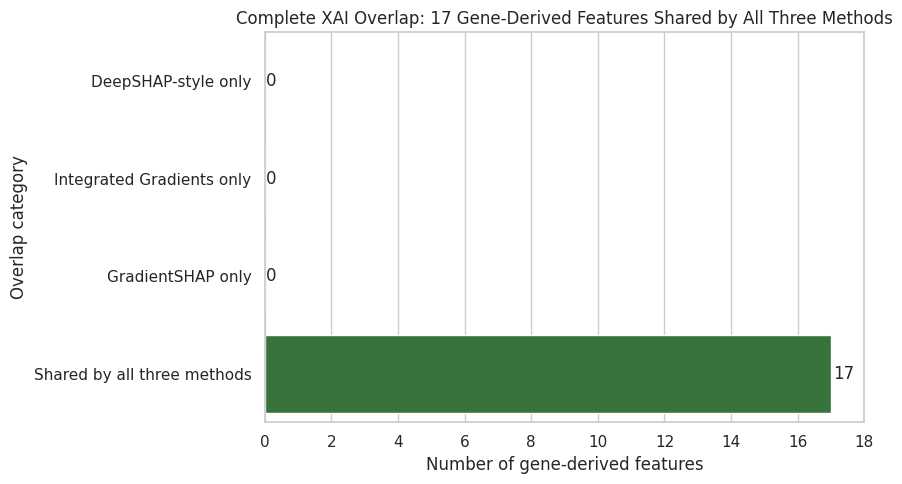

'/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/XAI/unicox_consensus_gene_venn_diagram.png'

In [12]:
all_three_overlap = deepshap_set & ig_set & gradientshap_set
only_deepshap = deepshap_set - ig_set - gradientshap_set
only_ig = ig_set - deepshap_set - gradientshap_set
only_gradientshap = gradientshap_set - deepshap_set - ig_set

all_sets_identical = (
    deepshap_set == ig_set
    and ig_set == gradientshap_set
)

if all_sets_identical:
    overlap_summary_df = pd.DataFrame({
        "overlap_category": [
            "DeepSHAP-style only",
            "Integrated Gradients only",
            "GradientSHAP only",
            "Shared by all three methods",
        ],
        "feature_count": [
            len(only_deepshap),
            len(only_ig),
            len(only_gradientshap),
            len(all_three_overlap),
        ],
    })

    shared_features_df = (
        pd.DataFrame({"feature": sorted(all_three_overlap)})
        .assign(
            gene_symbol=lambda df: df["feature"].apply(gene_symbol),
            readable_label=lambda df: df["feature"].apply(readable_label),
            alteration_type=lambda df: df["feature"].apply(alteration_type),
        )
    )

    print(
        "All three XAI methods selected the same gene-derived feature set. "
        "A standard Venn diagram would collapse into one circle, so a complete-overlap figure is shown instead."
    )
    display(overlap_summary_df)
    display(shared_features_df)

    plt.figure(figsize=(9, 5))
    colors = ["#D9D9D9", "#D9D9D9", "#D9D9D9", "#2E7D32"]
    sns.barplot(
        data=overlap_summary_df,
        x="feature_count",
        y="overlap_category",
        palette=colors
    )
    plt.xlabel("Number of gene-derived features")
    plt.ylabel("Overlap category")
    plt.title(
        f"Complete XAI Overlap: {len(all_three_overlap)} Gene-Derived Features Shared by All Three Methods"
    )
    plt.xlim(0, max(1, overlap_summary_df["feature_count"].max()) + 1)

    for index, value in enumerate(overlap_summary_df["feature_count"]):
        plt.text(value + 0.05, index, str(value), va="center")

    plt.tight_layout()
    plt.savefig(VENN_PLOT_PATH, dpi=300, bbox_inches="tight")
    plt.show()

else:
    plt.figure(figsize=(8, 7))
    venn3(
        [deepshap_set, ig_set, gradientshap_set],
        set_labels=("DeepSHAP-style", "Integrated Gradients", "GradientSHAP")
    )
    plt.title(f"Overlap of Top {TOP_N_GENES_PER_METHOD} Gene-Derived Features Across XAI Methods")
    plt.tight_layout()
    plt.savefig(VENN_PLOT_PATH, dpi=300, bbox_inches="tight")
    plt.show()

VENN_PLOT_PATH

Build consensus candidate table
A consensus candidate is defined as a gene-derived feature identified by at least two of the three XAI methods.

In [13]:
method_tables = {
    "deepshap": deepshap_top,
    "integrated_gradients": ig_top,
    "gradientshap": gradientshap_top,
}

all_features = sorted(deepshap_set | ig_set | gradientshap_set)

consensus_rows = []
for feature in all_features:
    row = {
        "feature": feature,
        "gene_symbol": gene_symbol(feature),
        "readable_label": readable_label(feature),
        "alteration_type": alteration_type(feature),
        "in_deepshap": feature in deepshap_set,
        "in_integrated_gradients": feature in ig_set,
        "in_gradientshap": feature in gradientshap_set,
    }

    row["method_count"] = int(
        row["in_deepshap"]
        + row["in_integrated_gradients"]
        + row["in_gradientshap"]
    )

    rank_values = []
    abs_values = []
    signed_values = []
    direction_values = []

    for method_key, method_df in method_tables.items():
        match = method_df[method_df["feature"] == feature]

        if match.empty:
            row[f"{method_key}_rank"] = np.nan
            row[f"{method_key}_mean_abs_attribution"] = np.nan
            row[f"{method_key}_mean_signed_attribution"] = np.nan
            row[f"{method_key}_direction"] = "Not identified"
            continue

        match_row = match.iloc[0]
        row[f"{method_key}_rank"] = match_row["method_gene_rank"]
        row[f"{method_key}_mean_abs_attribution"] = match_row["mean_abs_attribution"]
        row[f"{method_key}_mean_signed_attribution"] = match_row["mean_signed_attribution"]
        row[f"{method_key}_direction"] = match_row["direction"]

        rank_values.append(float(match_row["method_gene_rank"]))
        abs_values.append(float(match_row["mean_abs_attribution"]))
        signed_values.append(float(match_row["mean_signed_attribution"]))
        direction_values.append(match_row["direction"])

    row["mean_xai_rank"] = np.mean(rank_values) if rank_values else np.nan
    row["mean_abs_attribution_across_methods"] = np.mean(abs_values) if abs_values else np.nan
    row["mean_signed_attribution_across_methods"] = np.mean(signed_values) if signed_values else np.nan
    row["direction_consensus"] = direction_from_signed_value(row["mean_signed_attribution_across_methods"])

    identified_directions = [
        direction for direction in direction_values
        if direction in ["Risk-increasing", "Protective"]
    ]
    row["direction_agreement_count"] = max(
        identified_directions.count("Risk-increasing"),
        identified_directions.count("Protective")
    ) if identified_directions else 0

    consensus_rows.append(row)

consensus_all_df = pd.DataFrame(consensus_rows)

consensus_candidates = (
    consensus_all_df[
        consensus_all_df["method_count"] >= CONSENSUS_MIN_METHODS
    ]
    .sort_values(
        ["method_count", "mean_xai_rank", "mean_abs_attribution_across_methods"],
        ascending=[False, True, False]
    )
    .reset_index(drop=True)
)

print("All unique gene-derived features:", consensus_all_df.shape[0])
print("Consensus candidates identified by at least", CONSENSUS_MIN_METHODS, "methods:", consensus_candidates.shape[0])

consensus_candidates

All unique gene-derived features: 17
Consensus candidates identified by at least 2 methods: 17


,feature,gene_symbol,readable_label,alteration_type,in_deepshap,in_integrated_gradients,in_gradientshap,method_count,deepshap_rank,deepshap_mean_abs_attribution,...,integrated_gradients_direction,gradientshap_rank,gradientshap_mean_abs_attribution,gradientshap_mean_signed_attribution,gradientshap_direction,mean_xai_rank,mean_abs_attribution_across_methods,mean_signed_attribution_across_methods,direction_consensus,direction_agreement_count
0,MUT_KRAS,KRAS,KRAS mutation,Mutation,True,True,True,3,1,0.053392,...,Risk-increasing,1,0.053427,0.009429,Risk-increasing,1.333333,0.044607,0.014671,Risk-increasing,3
1,CNA_CDKN2A,CDKN2A,CDKN2A CNA,Copy number alteration,True,True,True,3,2,0.044873,...,Risk-increasing,2,0.049399,0.015241,Risk-increasing,1.666667,0.043865,0.021930,Risk-increasing,3
2,CNA_CDKN2Ap14ARF,CDKN2Ap14ARF,CDKN2Ap14ARF CNA,Copy number alteration,True,True,True,3,4,0.030566,...,Risk-increasing,4,0.034318,0.010134,Risk-increasing,3.666667,0.030108,0.014507,Risk-increasing,3
3,CNA_AXL,AXL,AXL CNA,Copy number alteration,True,True,True,3,3,0.033654,...,Protective,3,0.035687,-0.034618,Protective,4.333333,0.027081,-0.026725,Protective,3
4,MUT_CD276,CD276,CD276 mutation,Mutation,True,True,True,3,5,0.018830,...,Risk-increasing,5,0.020050,-0.006919,Protective,6.000000,0.015060,-0.002959,Protective,2
5,MUT_ARID1A,ARID1A,ARID1A mutation,Mutation,True,True,True,3,8,0.015835,...,Risk-increasing,6,0.017793,0.004794,Risk-increasing,6.333333,0.015887,0.007247,Risk-increasing,3
6,CNA_TP53,TP53,TP53 CNA,Copy number alteration,True,True,True,3,9,0.014232,...,Risk-increasing,8,0.017266,0.016064,Risk-increasing,7.000000,0.015928,0.015527,Risk-increasing,3
7,CNA_PPP2R1A,PPP2R1A,PPP2R1A CNA,Copy number alteration,True,True,True,3,6,0.016750,...,Protective,7,0.017295,-0.016835,Protective,8.666667,0.011423,-0.011270,Protective,3
8,CNA_CDKN2B,CDKN2B,CDKN2B CNA,Copy number alteration,True,True,True,3,10,0.007930,...,Risk-increasing,10,0.010275,0.000873,Risk-increasing,8.666667,0.010285,0.004129,Risk-increasing,3
9,CNA_POLD1,POLD1,POLD1 CNA,Copy number alteration,True,True,True,3,7,0.016610,...,Protective,9,0.017174,-0.016763,Protective,9.333333,0.011346,-0.011209,Protective,3


Load CoxPH model for direction comparison
The CoxPH model provides hazard ratios and coefficients. This lets us check whether XAI direction broadly agrees with the interpretable CoxPH direction for the same gene-derived feature.

In [14]:
with open(COXPH_MODEL_PATH, "rb") as file:
    cph_final = pickle.load(file)

cox_summary = cph_final.summary.copy()

cox_gene_table = cox_summary[[
    "coef",
    "exp(coef)",
    "exp(coef) lower 95%",
    "exp(coef) upper 95%",
    "p"
]].copy()

cox_gene_table = cox_gene_table.reset_index().rename(columns={
    "covariate": "feature",
    "coef": "coxph_coefficient",
    "exp(coef)": "coxph_hazard_ratio",
    "exp(coef) lower 95%": "coxph_hr_lower_95",
    "exp(coef) upper 95%": "coxph_hr_upper_95",
    "p": "coxph_p_value",
})

cox_gene_table = cox_gene_table[
    cox_gene_table["feature"].str.startswith(("MUT_", "CNA_"))
].copy()

cox_gene_table["coxph_direction"] = cox_gene_table["coxph_coefficient"].apply(direction_from_signed_value)
cox_gene_table["gene_symbol"] = cox_gene_table["feature"].apply(gene_symbol)
cox_gene_table["readable_label"] = cox_gene_table["feature"].apply(readable_label)

cox_gene_table.sort_values("coxph_p_value")

,feature,coxph_coefficient,coxph_hazard_ratio,coxph_hr_lower_95,coxph_hr_upper_95,coxph_p_value,coxph_direction,gene_symbol,readable_label
24,CNA_TP53,-1.242123,0.288770,0.170226,0.489870,0.000004,Protective,TP53,TP53 CNA
41,CNA_AXL,1.796440,6.028150,2.546584,14.269545,0.000044,Risk-increasing,AXL,AXL CNA
44,MUT_SHQ1,1.576031,4.835724,1.929153,12.121499,0.000775,Risk-increasing,SHQ1,SHQ1 mutation
33,CNA_POLD1,5.000000,148.413157,6.692768,3291.084490,0.001565,Risk-increasing,POLD1,POLD1 CNA
32,CNA_PPP2R1A,5.000000,148.413157,6.692768,3291.084490,0.001565,Risk-increasing,PPP2R1A,PPP2R1A CNA
36,MUT_CD276,2.419085,11.235573,2.330165,54.175612,0.002579,Risk-increasing,CD276,CD276 mutation
49,MUT_FGFR4,1.732219,5.653183,1.650471,19.363245,0.005822,Risk-increasing,FGFR4,FGFR4 mutation
40,CNA_HOXB13,1.070315,2.916299,1.359701,6.254903,0.005974,Risk-increasing,HOXB13,HOXB13 CNA
47,MUT_KRAS,0.265757,1.304418,1.026229,1.658018,0.029892,Risk-increasing,KRAS,KRAS mutation
37,CNA_WHSC1L1,-0.489005,0.613236,0.355978,1.056411,0.078035,Protective,WHSC1L1,WHSC1L1 CNA


Add CoxPH direction to consensus table

In [15]:
consensus_with_coxph = consensus_candidates.merge(
    cox_gene_table[[
        "feature",
        "coxph_coefficient",
        "coxph_hazard_ratio",
        "coxph_hr_lower_95",
        "coxph_hr_upper_95",
        "coxph_p_value",
        "coxph_direction",
    ]],
    on="feature",
    how="left"
)

consensus_with_coxph["xai_coxph_direction_agreement"] = (
    consensus_with_coxph["direction_consensus"]
    == consensus_with_coxph["coxph_direction"]
)

consensus_with_coxph

,feature,gene_symbol,readable_label,alteration_type,in_deepshap,in_integrated_gradients,in_gradientshap,method_count,deepshap_rank,deepshap_mean_abs_attribution,...,mean_signed_attribution_across_methods,direction_consensus,direction_agreement_count,coxph_coefficient,coxph_hazard_ratio,coxph_hr_lower_95,coxph_hr_upper_95,coxph_p_value,coxph_direction,xai_coxph_direction_agreement
0,MUT_KRAS,KRAS,KRAS mutation,Mutation,True,True,True,3,1,0.053392,...,0.014671,Risk-increasing,3,0.265757,1.304418,1.026229,1.658018,0.029892,Risk-increasing,True
1,CNA_CDKN2A,CDKN2A,CDKN2A CNA,Copy number alteration,True,True,True,3,2,0.044873,...,0.021930,Risk-increasing,3,-0.107883,0.897732,0.697454,1.155522,0.402239,Protective,False
2,CNA_CDKN2Ap14ARF,CDKN2Ap14ARF,CDKN2Ap14ARF CNA,Copy number alteration,True,True,True,3,4,0.030566,...,0.014507,Risk-increasing,3,-0.079904,0.923205,0.717282,1.188247,0.534916,Protective,False
3,CNA_AXL,AXL,AXL CNA,Copy number alteration,True,True,True,3,3,0.033654,...,-0.026725,Protective,3,1.796440,6.028150,2.546584,14.269545,0.000044,Risk-increasing,False
4,MUT_CD276,CD276,CD276 mutation,Mutation,True,True,True,3,5,0.018830,...,-0.002959,Protective,2,2.419085,11.235573,2.330165,54.175612,0.002579,Risk-increasing,False
5,MUT_ARID1A,ARID1A,ARID1A mutation,Mutation,True,True,True,3,8,0.015835,...,0.007247,Risk-increasing,3,0.068761,1.071180,0.886034,1.295015,0.477578,Risk-increasing,True
6,CNA_TP53,TP53,TP53 CNA,Copy number alteration,True,True,True,3,9,0.014232,...,0.015527,Risk-increasing,3,-1.242123,0.288770,0.170226,0.489870,0.000004,Protective,False
7,CNA_PPP2R1A,PPP2R1A,PPP2R1A CNA,Copy number alteration,True,True,True,3,6,0.016750,...,-0.011270,Protective,3,5.000000,148.413157,6.692768,3291.084490,0.001565,Risk-increasing,False
8,CNA_CDKN2B,CDKN2B,CDKN2B CNA,Copy number alteration,True,True,True,3,10,0.007930,...,0.004129,Risk-increasing,3,-0.030700,0.969766,0.785798,1.196805,0.774843,Protective,False
9,CNA_POLD1,POLD1,POLD1 CNA,Copy number alteration,True,True,True,3,7,0.016610,...,-0.011209,Protective,3,5.000000,148.413157,6.692768,3291.084490,0.001565,Risk-increasing,False


High-confidence consensus candidates -
High-confidence candidates appear in all three DeepSurv XAI methods.

In [16]:
high_confidence_candidates = consensus_with_coxph[
    consensus_with_coxph["method_count"] == 3
].copy()

print("High-confidence candidates:", high_confidence_candidates.shape[0])
high_confidence_candidates

High-confidence candidates: 17


,feature,gene_symbol,readable_label,alteration_type,in_deepshap,in_integrated_gradients,in_gradientshap,method_count,deepshap_rank,deepshap_mean_abs_attribution,...,mean_signed_attribution_across_methods,direction_consensus,direction_agreement_count,coxph_coefficient,coxph_hazard_ratio,coxph_hr_lower_95,coxph_hr_upper_95,coxph_p_value,coxph_direction,xai_coxph_direction_agreement
0,MUT_KRAS,KRAS,KRAS mutation,Mutation,True,True,True,3,1,0.053392,...,0.014671,Risk-increasing,3,0.265757,1.304418,1.026229,1.658018,0.029892,Risk-increasing,True
1,CNA_CDKN2A,CDKN2A,CDKN2A CNA,Copy number alteration,True,True,True,3,2,0.044873,...,0.021930,Risk-increasing,3,-0.107883,0.897732,0.697454,1.155522,0.402239,Protective,False
2,CNA_CDKN2Ap14ARF,CDKN2Ap14ARF,CDKN2Ap14ARF CNA,Copy number alteration,True,True,True,3,4,0.030566,...,0.014507,Risk-increasing,3,-0.079904,0.923205,0.717282,1.188247,0.534916,Protective,False
3,CNA_AXL,AXL,AXL CNA,Copy number alteration,True,True,True,3,3,0.033654,...,-0.026725,Protective,3,1.796440,6.028150,2.546584,14.269545,0.000044,Risk-increasing,False
4,MUT_CD276,CD276,CD276 mutation,Mutation,True,True,True,3,5,0.018830,...,-0.002959,Protective,2,2.419085,11.235573,2.330165,54.175612,0.002579,Risk-increasing,False
5,MUT_ARID1A,ARID1A,ARID1A mutation,Mutation,True,True,True,3,8,0.015835,...,0.007247,Risk-increasing,3,0.068761,1.071180,0.886034,1.295015,0.477578,Risk-increasing,True
6,CNA_TP53,TP53,TP53 CNA,Copy number alteration,True,True,True,3,9,0.014232,...,0.015527,Risk-increasing,3,-1.242123,0.288770,0.170226,0.489870,0.000004,Protective,False
7,CNA_PPP2R1A,PPP2R1A,PPP2R1A CNA,Copy number alteration,True,True,True,3,6,0.016750,...,-0.011270,Protective,3,5.000000,148.413157,6.692768,3291.084490,0.001565,Risk-increasing,False
8,CNA_CDKN2B,CDKN2B,CDKN2B CNA,Copy number alteration,True,True,True,3,10,0.007930,...,0.004129,Risk-increasing,3,-0.030700,0.969766,0.785798,1.196805,0.774843,Protective,False
9,CNA_POLD1,POLD1,POLD1 CNA,Copy number alteration,True,True,True,3,7,0.016610,...,-0.011209,Protective,3,5.000000,148.413157,6.692768,3291.084490,0.001565,Risk-increasing,False


Risk-increasing consensus candidates

In [17]:
risk_increasing_consensus = consensus_with_coxph[
    consensus_with_coxph["direction_consensus"] == "Risk-increasing"
].copy()

risk_increasing_consensus[[
    "feature",
    "gene_symbol",
    "alteration_type",
    "method_count",
    "mean_xai_rank",
    "mean_abs_attribution_across_methods",
    "mean_signed_attribution_across_methods",
    "direction_consensus",
    "coxph_hazard_ratio",
    "coxph_p_value",
    "coxph_direction",
    "xai_coxph_direction_agreement",
]]

,feature,gene_symbol,alteration_type,method_count,mean_xai_rank,mean_abs_attribution_across_methods,mean_signed_attribution_across_methods,direction_consensus,coxph_hazard_ratio,coxph_p_value,coxph_direction,xai_coxph_direction_agreement
0,MUT_KRAS,KRAS,Mutation,3,1.333333,0.044607,0.014671,Risk-increasing,1.304418,0.029892,Risk-increasing,True
1,CNA_CDKN2A,CDKN2A,Copy number alteration,3,1.666667,0.043865,0.021930,Risk-increasing,0.897732,0.402239,Protective,False
2,CNA_CDKN2Ap14ARF,CDKN2Ap14ARF,Copy number alteration,3,3.666667,0.030108,0.014507,Risk-increasing,0.923205,0.534916,Protective,False
5,MUT_ARID1A,ARID1A,Mutation,3,6.333333,0.015887,0.007247,Risk-increasing,1.071180,0.477578,Risk-increasing,True
6,CNA_TP53,TP53,Copy number alteration,3,7.000000,0.015928,0.015527,Risk-increasing,0.288770,0.000004,Protective,False
8,CNA_CDKN2B,CDKN2B,Copy number alteration,3,8.666667,0.010285,0.004129,Risk-increasing,0.969766,0.774843,Protective,False
11,MUT_SHQ1,SHQ1,Mutation,3,11.666667,0.003952,0.003369,Risk-increasing,4.835724,0.000775,Risk-increasing,True
12,CNA_WHSC1L1,WHSC1L1,Copy number alteration,3,12.000000,0.002898,0.002601,Risk-increasing,0.613236,0.078035,Protective,False
13,MUT_FGFR4,FGFR4,Mutation,3,14.000000,0.000842,0.000481,Risk-increasing,5.653183,0.005822,Risk-increasing,True
16,CNA_REL,REL,Copy number alteration,3,17.000000,0.000183,0.000016,Risk-increasing,2.083077,0.527448,Risk-increasing,True


Protective consensus candidates

In [18]:
protective_consensus = consensus_with_coxph[
    consensus_with_coxph["direction_consensus"] == "Protective"
].copy()

protective_consensus[[
    "feature",
    "gene_symbol",
    "alteration_type",
    "method_count",
    "mean_xai_rank",
    "mean_abs_attribution_across_methods",
    "mean_signed_attribution_across_methods",
    "direction_consensus",
    "coxph_hazard_ratio",
    "coxph_p_value",
    "coxph_direction",
    "xai_coxph_direction_agreement",
]]

,feature,gene_symbol,alteration_type,method_count,mean_xai_rank,mean_abs_attribution_across_methods,mean_signed_attribution_across_methods,direction_consensus,coxph_hazard_ratio,coxph_p_value,coxph_direction,xai_coxph_direction_agreement
3,CNA_AXL,AXL,Copy number alteration,3,4.333333,0.027081,-0.026725,Protective,6.028150,0.000044,Risk-increasing,False
4,MUT_CD276,CD276,Mutation,3,6.000000,0.015060,-0.002959,Protective,11.235573,0.002579,Risk-increasing,False
7,CNA_PPP2R1A,PPP2R1A,Copy number alteration,3,8.666667,0.011423,-0.011270,Protective,148.413157,0.001565,Risk-increasing,False
9,CNA_POLD1,POLD1,Copy number alteration,3,9.333333,0.011346,-0.011209,Protective,148.413157,0.001565,Risk-increasing,False
10,CNA_CDKN2Ap16INK4A,CDKN2Ap16INK4A,Copy number alteration,3,10.333333,0.007307,-0.000397,Protective,0.960009,0.745206,Protective,True
14,CNA_HOXB13,HOXB13,Copy number alteration,3,15.000000,0.000269,-0.000006,Protective,2.916299,0.005974,Risk-increasing,False
15,CNA_XPO1,XPO1,Copy number alteration,3,16.000000,0.000202,-0.000020,Protective,2.083077,0.527448,Risk-increasing,False


Consensus gene ranking bar plot

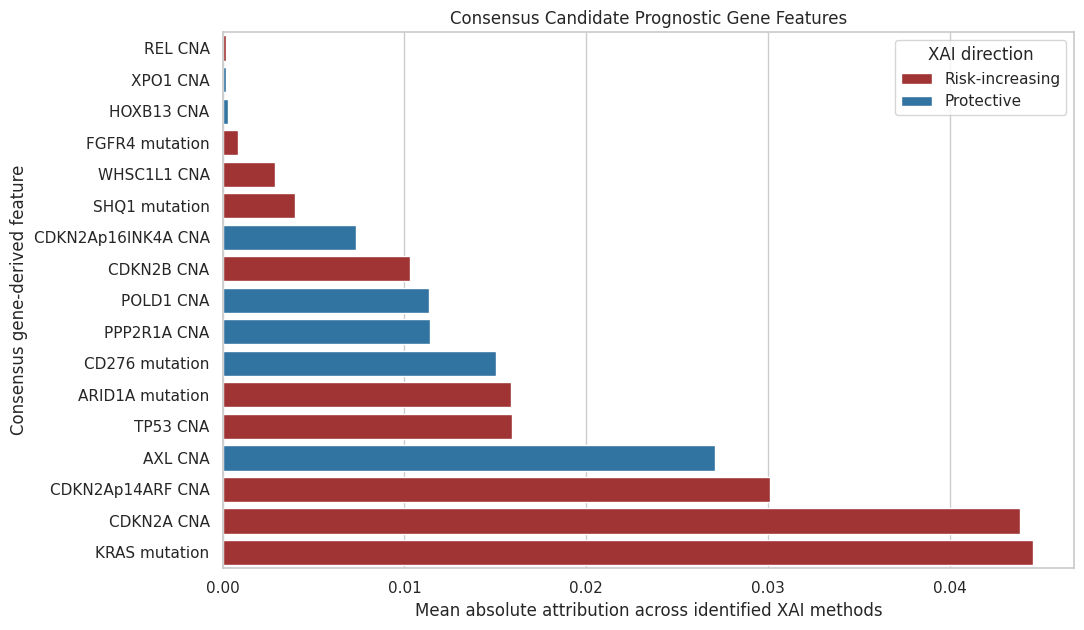

'/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/XAI/unicox_consensus_gene_ranking_barplot.png'

In [19]:
plot_df = consensus_with_coxph.head(TOP_N_DISPLAY).copy()
plot_df = plot_df.sort_values("mean_abs_attribution_across_methods", ascending=True)

plt.figure(figsize=(11, max(6, 0.38 * plot_df.shape[0])))
sns.barplot(
    data=plot_df,
    x="mean_abs_attribution_across_methods",
    y="readable_label",
    hue="direction_consensus",
    dodge=False,
    palette={"Risk-increasing": "#B22222", "Protective": "#1F77B4", "Neutral": "gray"}
)
plt.xlabel("Mean absolute attribution across identified XAI methods")
plt.ylabel("Consensus gene-derived feature")
plt.title("Consensus Candidate Prognostic Gene Features")
plt.legend(title="XAI direction")
plt.tight_layout()
plt.savefig(BAR_PLOT_PATH, dpi=300, bbox_inches="tight")
plt.show()

BAR_PLOT_PATH

Direction heatmap across XAI methods

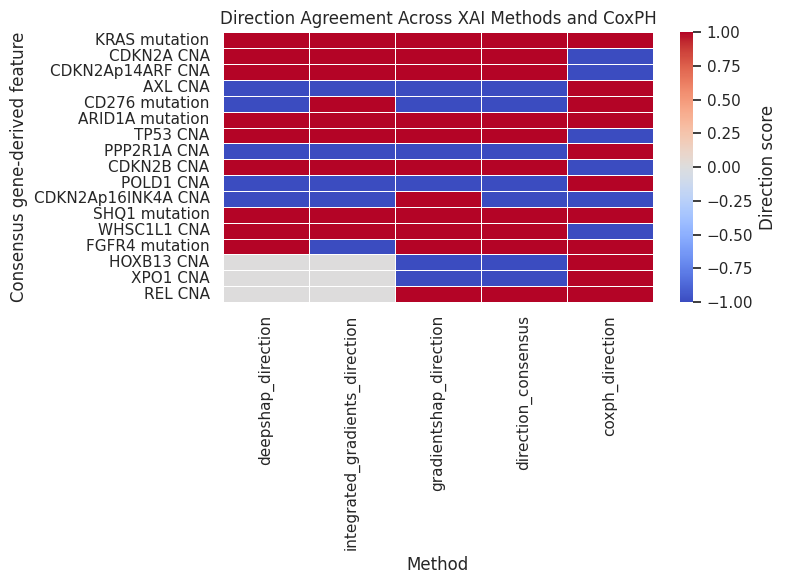

'/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/XAI/unicox_consensus_gene_direction_heatmap.png'

In [20]:
heatmap_df = consensus_with_coxph.head(TOP_N_DISPLAY).copy()

direction_score_map = {
    "Risk-increasing": 1,
    "Protective": -1,
    "Neutral": 0,
    "Not identified": np.nan,
}

direction_matrix = heatmap_df.set_index("readable_label")[[
    "deepshap_direction",
    "integrated_gradients_direction",
    "gradientshap_direction",
    "direction_consensus",
    "coxph_direction",
]].replace(direction_score_map)

plt.figure(figsize=(8, max(6, 0.35 * direction_matrix.shape[0])))
sns.heatmap(
    direction_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Direction score"}
)
plt.title("Direction Agreement Across XAI Methods and CoxPH")
plt.xlabel("Method")
plt.ylabel("Consensus gene-derived feature")
plt.tight_layout()
plt.savefig(DIRECTION_HEATMAP_PATH, dpi=300, bbox_inches="tight")
plt.show()

DIRECTION_HEATMAP_PATH

Save final consensus outputs

In [21]:
consensus_with_coxph.to_csv(CONSENSUS_TABLE_PATH, index=False)
consensus_with_coxph.head(TOP_N_DISPLAY).to_csv(CONSENSUS_TOP_TABLE_PATH, index=False)

print("Saved full consensus table to:", CONSENSUS_TABLE_PATH)
print("Saved top consensus table to:", CONSENSUS_TOP_TABLE_PATH)
print("Saved Venn diagram to:", VENN_PLOT_PATH)
print("Saved ranking bar plot to:", BAR_PLOT_PATH)
print("Saved direction heatmap to:", DIRECTION_HEATMAP_PATH)

Saved full consensus table to: /content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/XAI/unicox_consensus_candidate_prognostic_gene_features.csv
Saved top consensus table to: /content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/XAI/unicox_consensus_candidate_prognostic_gene_features_top.csv
Saved Venn diagram to: /content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/XAI/unicox_consensus_gene_venn_diagram.png
Saved ranking bar plot to: /content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/XAI/unicox_consensus_gene_ranking_barplot.png
Saved direction heatmap to: /content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/XAI/unicox_consensus_gene_direction_heatmap.png


Final consensus conclusion
This notebook identifies candidate prognostic gene-derived features that are consistently ranked by DeepSurv XAI methods. Features appearing in at least two methods are treated as consensus candidates, while features appearing in all three methods are treated as high-confidence candidates. The CoxPH comparison adds direction and hazard-ratio context from the best-performing interpretable model. These consensus outputs provide the candidate prognostic gene list and supporting visual evidence for the explainability component of the research.